**Data exploration**

In [4]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [18]:
# Function: Load the two datasets
def load_data(csv_path, geo_path):
    df = pd.read_csv(csv_path, low_memory=False)
    countries = gpd.read_file(geo_path)

    return df, countries

In [19]:
DATA_DIR = Path("../data")

df, countries = load_data(
    DATA_DIR / "raw/TWO_CENTURIES_OF_UM_RACES.csv",
    DATA_DIR / "countries_shp/ne_110m_admin_0_countries.shp"
)

print("Ultra-marathon dataset:", df.shape)
print("Geographical dataset:", countries.shape)

Ultra-marathon dataset: (7117634, 13)
Geographical dataset: (177, 64)


In [17]:
display(df.head())
display(countries.head())

,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete club,Athlete country,Athlete year of birth,Athlete gender,Athlete age category,Athlete average speed,Athlete ID
0,2018,06.01.2018,Selva Costera (CHI),50km,22,4:51:39 h,Tnfrc,CHI,1978.0,M,M35,10.286,0
1,2018,06.01.2018,Selva Costera (CHI),50km,22,5:15:45 h,Roberto Echeverría,CHI,1981.0,M,M35,9.501,1
2,2018,06.01.2018,Selva Costera (CHI),50km,22,5:16:44 h,Puro Trail Osorno,CHI,1987.0,M,M23,9.472,2
3,2018,06.01.2018,Selva Costera (CHI),50km,22,5:34:13 h,Columbia,ARG,1976.0,M,M40,8.976,3
4,2018,06.01.2018,Selva Costera (CHI),50km,22,5:54:14 h,Baguales Trail,CHI,1992.0,M,M23,8.469,4


,scalerank,featurecla,labelrank,sovereignt,sov_a3,adm0_dif,level,type,admin,adm0_a3,...,continent,region_un,subregion,region_wb,name_len,long_len,abbrev_len,tiny,homepart,geometry
0,1,Admin-0 country,3.0,Afghanistan,AFG,0.0,2.0,Sovereign country,Afghanistan,AFG,...,Asia,Asia,Southern Asia,South Asia,11.0,11.0,4.0,-99.0,1.0,"POLYGON ((61.21082 35.65007, 62.23065 35.27066..."
1,1,Admin-0 country,3.0,Angola,AGO,0.0,2.0,Sovereign country,Angola,AGO,...,Africa,Africa,Middle Africa,Sub-Saharan Africa,6.0,6.0,4.0,-99.0,1.0,"MULTIPOLYGON (((16.32653 -5.87747, 16.57318 -6..."
2,1,Admin-0 country,6.0,Albania,ALB,0.0,2.0,Sovereign country,Albania,ALB,...,Europe,Europe,Southern Europe,Europe & Central Asia,7.0,7.0,4.0,-99.0,1.0,"POLYGON ((20.59025 41.8554, 20.46318 41.51509,..."
3,1,Admin-0 country,4.0,United Arab Emirates,ARE,0.0,2.0,Sovereign country,United Arab Emirates,ARE,...,Asia,Asia,Western Asia,Middle East & North Africa,20.0,20.0,6.0,-99.0,1.0,"POLYGON ((51.57952 24.2455, 51.75744 24.29407,..."
4,1,Admin-0 country,2.0,Argentina,ARG,0.0,2.0,Sovereign country,Argentina,ARG,...,South America,Americas,South America,Latin America & Caribbean,9.0,9.0,4.0,-99.0,1.0,"MULTIPOLYGON (((-65.5 -55.2, -66.45 -55.25, -6..."


### 1.1 Dataset overview

This section explores the structure, data types, missing values
and statistical characteristics of both datasets.

In [10]:
print("Ultra-marathon dataset:", df.shape)
print("Geographical dataset:", countries.shape)

df.info()

Ultra-marathon dataset: (7117634, 13)
Geographical dataset: (177, 64)
<class 'pandas.DataFrame'>
RangeIndex: 7117634 entries, 0 to 7117633
Data columns (total 13 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   Year of event              int64  
 1   Event dates                str    
 2   Event name                 str    
 3   Event distance/length      str    
 4   Event number of finishers  int64  
 5   Athlete performance        str    
 6   Athlete club               str    
 7   Athlete country            str    
 8   Athlete year of birth      float64
 9   Athlete gender             str    
 10  Athlete age category       str    
 11  Athlete average speed      str    
 12  Athlete ID                 int64  
dtypes: float64(1), int64(3), str(9)
memory usage: 705.9 MB


In [11]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Percentage (%)": df.isna().mean() * 100
})

display(missing.round(2))

,Missing values,Percentage (%)
Year of event,0,0.00
Event dates,0,0.00
Event name,0,0.00
Event distance/length,1053,0.01
Event number of finishers,0,0.00
Athlete performance,2,0.00
Athlete club,2672972,37.55
Athlete country,3,0.00
Athlete year of birth,559354,7.86
Athlete gender,4,0.00


In [13]:
display(df.describe())

,Year of event,Event number of finishers,Athlete year of birth,Athlete ID
count,7.117634e+06,7.117634e+06,6.558280e+06,7.117634e+06
mean,2.012990e+03,1.310716e+03,1.970613e+03,5.275223e+05
std,9.074683e+00,2.973447e+03,1.264591e+01,4.634639e+05
min,1.798000e+03,0.000000e+00,1.193000e+03,0.000000e+00
25%,2.011000e+03,8.700000e+01,1.963000e+03,1.304470e+05
50%,2.016000e+03,2.270000e+02,1.972000e+03,3.775990e+05
75%,2.019000e+03,7.690000e+02,1.980000e+03,9.164148e+05
max,2.022000e+03,2.002700e+04,2.021000e+03,1.600755e+06


In [14]:
display(df.describe(include="object"))

C:\Users\aurel\AppData\Local\Temp\ipykernel_28224\1391311326.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Event dates,Event name,Event distance/length,Athlete performance,Athlete club,Athlete country,Athlete gender,Athlete age category,Athlete average speed
count,7117634,7117634,7116581,7117632,4444662,7117631,7117630,6561405,7117410
unique,12991,26246,2131,313108,538439,206,3,37,18295
top,20.04.2019,Two Oceans Marathon (RSA),50km,50.000 km,*Tokyo,USA,M,M23,4.167
freq,29176,204658,1503475,5676,26778,1347363,5724465,1140466,4514


In [15]:
print("Number of duplicates:", df.duplicated().sum())

Number of duplicates: 50


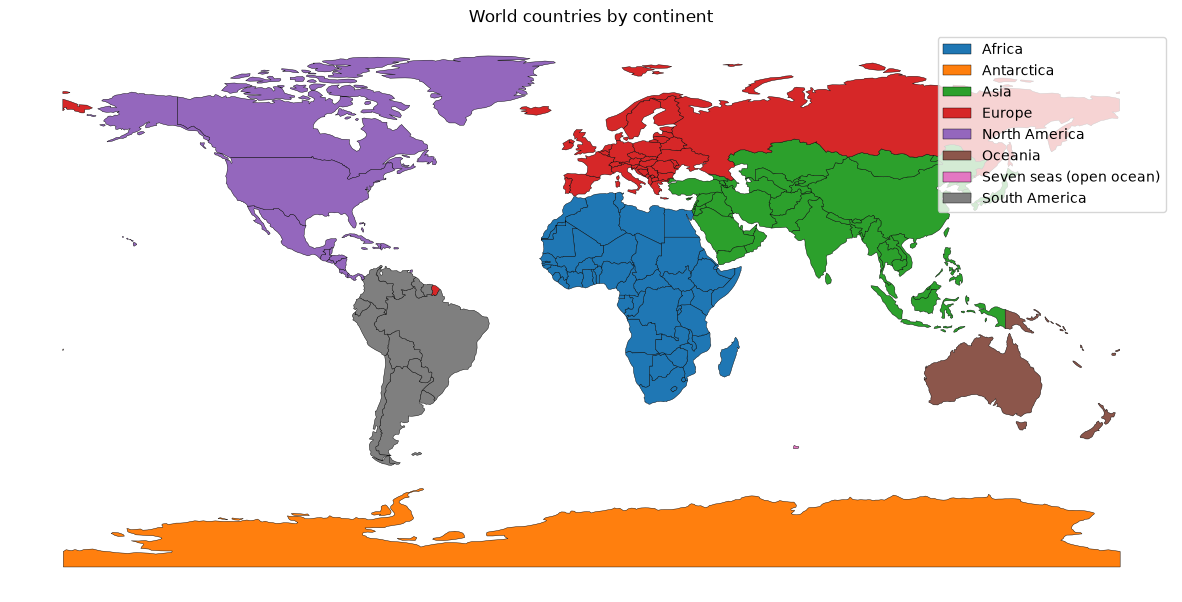

In [16]:
countries.plot(
    column="continent",
    figsize=(15, 8),
    legend=True,
    edgecolor="black",
    linewidth=0.3
)

plt.title("World countries by continent")
plt.axis("off")
plt.show()

In [20]:
display(df["Event distance/length"].value_counts().head(40))

Event distance/length
50km      1503475
100km      883268
50mi       333685
56km       274234
24h        172811
100mi      164750
87km       162087
60km       156806
45km       155475
89km       143541
55km       129700
6h         123943
12h        111792
80km        94885
52km        92513
70km        82660
65km        80089
53km        69225
75km        62428
48km        61590
46km        60038
90km        59493
63km        56926
72km        52358
51km        52188
54km        51243
47km        41145
58km        37405
57km        36969
68km        36486
73km        35643
62km        33943
78km        31464
110km       30316
101km       30098
71.5km      30080
69km        29594
40mi        28937
72.7km      28676
67km        28033
Name: count, dtype: int64

In [22]:
print("First year:", df["Year of event"].min())
print("Last year:", df["Year of event"].max())

print("Number of unique athletes:", df["Athlete ID"].nunique())
print("Number of duplicates:", df.duplicated().sum())

First year: 1798
Last year: 2022
Number of unique athletes: 1600756
Number of duplicates: 50


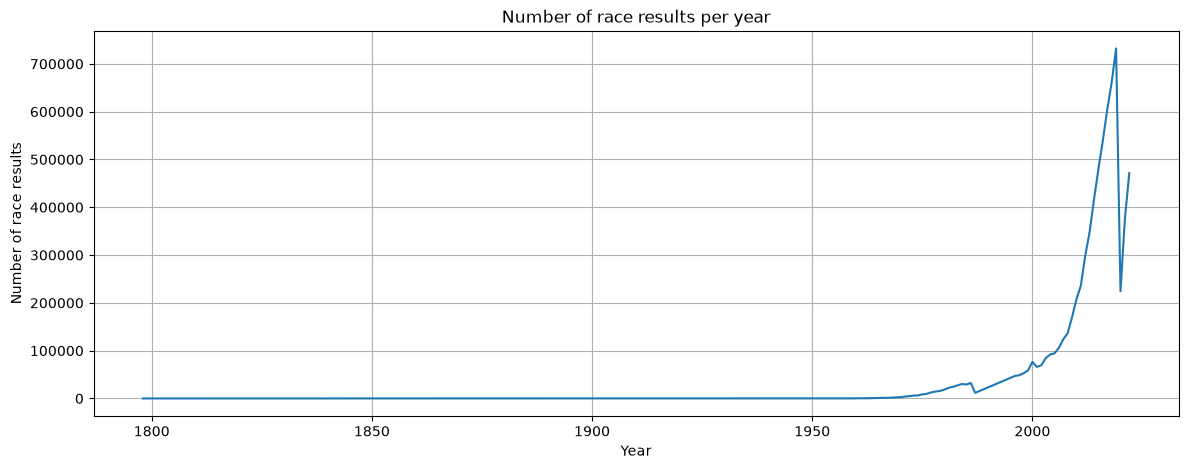

In [21]:
df.groupby("Year of event").size().plot(
    kind="line",
    figsize=(14, 5),
    title="Number of race results per year",
    grid=True
)

plt.xlabel("Year")
plt.ylabel("Number of race results")
plt.show()

In [24]:
event_country = df["Event name"].str.extract(
    r"\(([A-Z]{2,3})\)\s*$"
)[0]

print("Identified countries (%):")
print(event_country.notna().mean() * 100)

print("\nNumber of different country codes:")
print(event_country.nunique())

display(event_country.value_counts().head(30))

Identified countries (%):
99.97715532998747

Number of different country codes:
125


0
USA    1365325
FRA    1122346
RSA     767240
JPN     588906
ITA     374617
GER     319162
GBR     311749
ESP     232121
CHN     214614
SUI     192192
TPE     146595
AUS     140236
POL     106139
CAN      90766
HKG      77826
KOR      75529
SWE      67374
BEL      62342
AUT      54692
PHI      47457
THA      46496
NED      45939
MAS      43933
HUN      42793
RUS      37392
POR      37204
ARG      34284
NZL      33914
NOR      33497
CZE      30449
Name: count, dtype: int64

In [ ]:
race_codes = set(event_country.dropna().unique())
geo_codes = set(countries["adm0_a3"].dropna().unique())

common_codes = race_codes & geo_codes
unmatched_codes = race_codes - geo_codes

print("Matching country codes:", len(common_codes))
print("Unmatched country codes:", len(unmatched_codes))

print(sorted(unmatched_codes))

#To see codes in the marathon dataset who don't fit with isoA3

Matching country codes: 68
Unmatched country codes: 57
['ALG', 'AND', 'ARU', 'BHU', 'BOT', 'BRU', 'BUL', 'BUR', 'CAM', 'CAY', 'CHA', 'CHI', 'CPV', 'CRC', 'CRO', 'DEN', 'ESA', 'GER', 'GRE', 'GUA', 'HKG', 'INA', 'IRI', 'IVB', 'KSA', 'LAT', 'LBA', 'LES', 'MAD', 'MAS', 'MGL', 'MLT', 'MON', 'MRI', 'MTN', 'MYA', 'NCA', 'NED', 'NEP', 'OMA', 'PAR', 'PHI', 'POR', 'PUR', 'RSA', 'SEY', 'SGP', 'SLO', 'SRI', 'STP', 'SUI', 'TPE', 'TRI', 'UAE', 'URU', 'VIE', 'ZIM']


In [ ]:
country_mapping = {
    "ALG": "DZA",
    "ARU": "ABW",
    "BHU": "BTN",
    "BOT": "BWA",
    "BRU": "BRN",
    "BUL": "BGR",
    "BUR": "BFA",
    "CAM": "KHM",
    "CAY": "CYM",
    "CHA": "TCD",
    "CHI": "CHL",
    "CRC": "CRI",
    "CRO": "HRV",
    "DEN": "DNK",
    "ESA": "SLV",
    "GER": "DEU",
    "GRE": "GRC",
    "GUA": "GTM",
    "INA": "IDN",
    "IRI": "IRN",
    "IVB": "VGB",
    "KSA": "SAU",
    "LAT": "LVA",
    "LBA": "LBY",
    "LES": "LSO",
    "MAD": "MDG",
    "MAS": "MYS",
    "MGL": "MNG",
    "MON": "MCO",
    "MRI": "MUS",
    "MTN": "MRT",
    "MYA": "MMR",
    "NCA": "NIC",
    "NED": "NLD",
    "NEP": "NPL",
    "OMA": "OMN",
    "PAR": "PRY",
    "PHI": "PHL",
    "POR": "PRT",
    "PUR": "PRI",
    "RSA": "ZAF",
    "SEY": "SYC",
    "SLO": "SVN",
    "SRI": "LKA",
    "SUI": "CHE",
    "TPE": "TWN",
    "TRI": "TTO",
    "UAE": "ARE",
    "URU": "URY",
    "VIE": "VNM",
    "ZIM": "ZWE"
}

#Rectification of country codes in the marathon dataset to match the geographical dataset

In [27]:
df["Event country"] = event_country.replace(country_mapping)

df["Athlete country ISO"] = df["Athlete country"].replace(
    country_mapping
)

race_codes = set(df["Event country"].dropna().unique())
geo_codes = set(countries["adm0_a3"].dropna().unique())

common_codes = race_codes & geo_codes
unmatched_codes = race_codes - geo_codes

print("Matching country codes:", len(common_codes))
print("Unmatched country codes:", len(unmatched_codes))

print(sorted(unmatched_codes))

print("\nPercentage of geographically matched results:")
print(df["Event country"].isin(geo_codes).mean() * 100)

Matching country codes: 113
Unmatched country codes: 12
['ABW', 'AND', 'CPV', 'CYM', 'HKG', 'MCO', 'MLT', 'MUS', 'SGP', 'STP', 'SYC', 'VGB']

Percentage of geographically matched results:
98.51560223523715


In [29]:
display(
    df.loc[
        ~df["Event country"].isin(geo_codes),
        "Event country"
    ].value_counts(dropna=False)
)

Event country
HKG    77826
SGP    12225
AND     6420
MUS     3161
MCO     3050
NaN     1626
MLT      646
CPV      342
VGB      158
STP      103
CYM       68
ABW       19
SYC       10
Name: count, dtype: int64

In [30]:
missing_continents = {
    "HKG": "Asia",
    "SGP": "Asia",
    "AND": "Europe",
    "MUS": "Africa",
    "MCO": "Europe",
    "MLT": "Europe",
    "CPV": "Africa",
    "VGB": "North America",
    "STP": "Africa",
    "CYM": "North America",
    "ABW": "North America",
    "SYC": "Africa"
}

In [31]:
geo_data = countries[[
    "adm0_a3",
    "admin",
    "continent",
    "subregion"
]].copy()

geo_data = geo_data.rename(columns={
    "adm0_a3": "Event country",
    "admin": "Country name",
    "continent": "Continent",
    "subregion": "Subregion"
})

df = df.merge(
    geo_data,
    on="Event country",
    how="left",
    validate="many_to_one"
)

df["Continent"] = df["Continent"].fillna(
    df["Event country"].map(missing_continents)
)

In [32]:
display(df["Continent"].value_counts(dropna=False))

print("Missing continents:", df["Continent"].isna().sum())

print("Dataset shape:", df.shape)

Continent
Europe           3270814
North America    1485332
Asia             1305401
Africa            798475
Oceania           174150
South America      81829
NaN                 1626
Antarctica             7
Name: count, dtype: int64

Missing continents: 1626
Dataset shape: (7117634, 19)


In [33]:
print(df.columns.tolist())

['Year of event', 'Event dates', 'Event name', 'Event distance/length', 'Event number of finishers', 'Athlete performance', 'Athlete club', 'Athlete country', 'Athlete year of birth', 'Athlete gender', 'Athlete age category', 'Athlete average speed', 'Athlete ID', 'Event country', 'Athlete country ISO', 'Race unit', 'Country name', 'Continent', 'Subregion']


In [34]:
df["Race value"] = pd.to_numeric(
    df["Event distance/length"].str.extract(
        r"^(\d+(?:\.\d+)?)"
    )[0],
    errors="coerce"
)

display(df["Race unit"].value_counts(dropna=False))

df["Distance km"] = np.nan

mask_km = df["Race unit"] == "km"
mask_mi = df["Race unit"] == "mi"

df.loc[mask_km, "Distance km"] = df.loc[mask_km, "Race value"]

df.loc[mask_mi, "Distance km"] = (
    df.loc[mask_mi, "Race value"] * 1.609344
)

Race unit
km         5780247
mi          735047
h           498291
etappen      90563
d            10968
NaN           1174
miles          498
stages         454
k              211
mile           122
m               40
split           19
Name: count, dtype: int64

In [35]:
df["Athlete average speed"] = pd.to_numeric(
    df["Athlete average speed"],
    errors="coerce"
)

display(df["Athlete average speed"].describe())

count    7.109734e+06
mean     7.264386e+00
std      2.279354e+00
min      0.000000e+00
25%      5.672000e+00
50%      7.161000e+00
75%      8.616000e+00
max      1.010000e+02
Name: Athlete average speed, dtype: float64

In [36]:
df["Athlete age"] = (
    df["Year of event"] - df["Athlete year of birth"]
)

display(df["Athlete age"].describe())

count    6.558280e+06
mean     4.254452e+01
std      9.977737e+00
min     -3.000000e+01
25%      3.500000e+01
50%      4.200000e+01
75%      4.900000e+01
max      8.270000e+02
Name: Athlete age, dtype: float64

In [37]:
display(df[[
    "Athlete age",
    "Athlete average speed",
    "Distance km"
]].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))

,Athlete age,Athlete average speed,Distance km
count,6.558280e+06,7.109734e+06,6.515294e+06
mean,4.254452e+01,7.264386e+00,7.562955e+01
std,9.977737e+00,2.279354e+00,4.549817e+01
min,-3.000000e+01,0.000000e+00,4.000000e+00
1%,2.200000e+01,2.897000e+00,4.500000e+01
5%,2.700000e+01,3.904000e+00,4.800000e+01
50%,4.200000e+01,7.161000e+00,6.500000e+01
95%,6.000000e+01,1.113500e+01,1.480000e+02
99%,6.700000e+01,1.325400e+01,1.750000e+02
max,8.270000e+02,1.010000e+02,5.000000e+03


In [38]:
invalid_age = (
    (df["Athlete age"] < 5) |
    (df["Athlete age"] > 100)
)

invalid_speed = (
    (df["Athlete average speed"] <= 0) |
    (df["Athlete average speed"] > 25)
)

print("Invalid ages:", invalid_age.sum())
print("Invalid speeds:", invalid_speed.sum())

print("Distances below 42.195 km:",
      (df["Distance km"] < 42.195).sum())

print("Distances above 1000 km:",
      (df["Distance km"] > 1000).sum())

Invalid ages: 64
Invalid speeds: 6061
Distances below 42.195 km: 85
Distances above 1000 km: 568


In [39]:
display(
    df.loc[df["Distance km"] < 42.195, [
        "Event name",
        "Event distance/length",
        "Distance km"
    ]].drop_duplicates().head(30)
)

,Event name,Event distance/length,Distance km
2103612,Notchview Ultra Quadzilla Ultra (USA),4x52km,4.0
3289931,Ultraroztocze 120km (POL),24.5km,24.5
5836015,Transeuropalauf 2012 Etappe 53 Motilla Del Pal...,39km,39.0


In [40]:
display(
    df.loc[df["Distance km"] > 1000, [
        "Event name",
        "Event distance/length",
        "Distance km"
    ]].drop_duplicates().head(30)
)

,Event name,Event distance/length,Distance km
38885,Iditarod Trail Invitational 1000 Miles (USA),1000mi,1609.3440
282154,Across Honshu Lengthwise Foot Race (JPN),1521km,1521.0000
404474,Self-Transcendence 3100 Mile Race (USA),3100mi,4988.9664
404480,Self-Transcendence 3100 Mile Race - 1000mi Spl...,1000mi,1609.3440
551891,Korea tour 1000 km (KOR),1008km,1008.0000
1087295,Korea tour 2500 km (KOR),2500km,2500.0000
1215760,1000 Miles Athens Int. Ultramarathon Festival ...,1000mi,1609.3440
1643203,Ultimate Circuits South Africa 16 Day Challeng...,1000mi,1609.3440
2477014,Running Festival Wychwood December 20 Days - 1...,1000mi,1609.3440
2527732,La 1000 (MTN),1040km,1040.0000


In [41]:
df.loc[invalid_age, "Athlete age"] = np.nan

df.loc[invalid_speed, "Athlete average speed"] = np.nan

### Outlier detection and treatment

The descriptive statistics revealed inconsistent values,
including negative ages, ages above 100 years and unrealistic
running speeds.

Invalid ages and speeds were replaced with missing values
rather than removing entire records, allowing these records
to remain available for temporal and spatial analyses.

Extreme race distances are investigated separately because
multi-day ultra-marathon events may legitimately cover
very long distances.

In [42]:
display(
    df.loc[
        df["Event distance/length"].str.contains("x", case=False, na=False),
        "Event distance/length"
    ].value_counts()
)

Event distance/length
4x52km    4
Name: count, dtype: int64

In [43]:
multiple = df["Event distance/length"].str.extract(
    r"^(\d+)\s*x\s*(\d+(?:\.\d+)?)\s*km$"
)

mask = multiple[0].notna()

df.loc[mask, "Distance km"] = (
    multiple.loc[mask, 0].astype(float) *
    multiple.loc[mask, 1].astype(float)
)

print("Corrected records:", mask.sum())

Corrected records: 4


In [44]:
df["Below marathon distance"] = df["Distance km"] < 42.195

display(df["Below marathon distance"].value_counts())

Below marathon distance
False    7117553
True          81
Name: count, dtype: int64

In [45]:
# Remove races shorter than or equal to a marathon
initial_rows = len(df)

df = df.loc[
    (df["Distance km"] > 42.195) |
    (df["Distance km"].isna())
].copy()

# Remove the unnecessary boolean column
df = df.drop(columns=["Below marathon distance"], errors="ignore")

print("Removed records:", initial_rows - len(df))
print("Dataset shape:", df.shape)

Removed records: 81
Dataset shape: (7117553, 22)


Fixed-distance race results with a distance of 42.195 km
or less were removed because they do not meet the definition
of an ultra-marathon. These records represent a negligible
proportion of the dataset. Fixed-duration events were retained.

In [46]:
df["Race type"] = "Other"

df.loc[df["Race unit"].isin(["km", "mi"]),
       "Race type"] = "Fixed distance"

df.loc[df["Race unit"].isin(["h", "d"]),
       "Race type"] = "Fixed duration"

display(df["Race type"].value_counts())

Race type
Fixed distance    6515213
Fixed duration     509259
Other               93081
Name: count, dtype: int64

In [47]:
df["Duration hours"] = np.nan

mask_h = df["Race unit"] == "h"
mask_d = df["Race unit"] == "d"

df.loc[mask_h, "Duration hours"] = df.loc[mask_h, "Race value"]

df.loc[mask_d, "Duration hours"] = df.loc[mask_d, "Race value"] * 24

display(df["Duration hours"].value_counts().head(20))

Duration hours
24.0     172811
6.0      124116
12.0     111898
8.0       21864
48.0      15651
144.0      8122
10.0       6392
16.0       3367
72.0       3029
30.0       2507
15.0       2134
28.0       2068
32.0       1729
36.0       1685
9.0        1573
33.0       1435
35.0       1363
26.0       1359
25.0       1357
7.0        1256
Name: count, dtype: int64

In [48]:
display(
    df["Event dates"].drop_duplicates().sample(
        30, random_state=42
    )
)

4670290           27.05.2006
3217899       02.-07.04.2022
3807018       17.-23.06.1984
3753409       06.-07.08.1982
3666138       03.-04.09.1977
5040921       23.-25.01.2009
1626677       04.-05.08.2017
3340967           01.07.2022
4820635       28.-30.04.2007
4669971    31.05.-01.06.2006
715894        07.-09.01.2016
3690391           22.04.1978
5000174           27.04.2009
3610135       02.-03.09.1892
3676073           16.04.1977
3893941           03.10.1987
1037996       13.-15.10.2016
3754301       09.-10.07.1982
1756490           26.11.2017
1956264           31.03.2019
2269718       14.-15.07.2019
4402961           11.02.2003
1097          24.-26.03.2018
3799967       23.-25.11.1984
2926688       25.-28.06.2021
6352932       07.-11.07.2014
3018482       16.-19.10.2021
4337556           06.10.2003
4229076       25.-26.05.2001
5218256    25.04.-01.05.2010
Name: Event dates, dtype: str

In [49]:
df["Intermediate result"] = df["Event name"].str.contains(
    r"\bsplits?\b|\betappe\b",
    case=False,
    na=False
)

display(df["Intermediate result"].value_counts())

Intermediate result
False    6909899
True      207654
Name: count, dtype: int64

In [50]:
display(
    df.loc[df["Race type"] == "Other",
           "Event distance/length"]
    .value_counts()
    .head(30)
)

Event distance/length
250km/6Etappen      9192
100km/2Etappen      3817
250.7km/6Etappen    2576
237km/6Etappen      2309
66mi/2Etappen       1835
100km/3Etappen      1795
220km/6Etappen      1538
230km/6Etappen      1497
120km/3Etappen      1368
249km/6Etappen      1237
110km/2Etappen      1227
195.4km/4Etappen    1226
111km/2Etappen      1190
243km/6Etappen      1181
163.6km/4Etappen    1125
84mi/3Etappen       1104
92km/2Etappen       1018
150km/3Etappen       973
257km/6Etappen       973
245km/6Etappen       945
293km/8Etappen       932
244km/6Etappen       917
247km/7Etappen       880
132km/2Etappen       857
169km/4Etappen       785
196km/4Etappen       778
202.2km/4Etappen     770
70km/2Etappen        759
245.3km/6Etappen     747
245.7km/6Etappen     731
Name: count, dtype: int64

In [51]:
# Remove unsupported race formats
initial_rows = len(df)

df = df[df["Race type"] != "Other"].copy()

print("Removed records:", initial_rows - len(df))
print("Dataset shape:", df.shape)

display(df["Race type"].value_counts())

Removed records: 93081
Dataset shape: (7024472, 25)


Race type
Fixed distance    6515213
Fixed duration     509259
Name: count, dtype: int64

Race formats classified as "Other", including stage races,
were excluded to focus on standard fixed-distance and
fixed-duration events. These records represented only
1.31% of the dataset.

In [52]:
# Date cleaning function
def parse_event_dates(value):

    if pd.isna(value):
        return pd.NaT, pd.NaT

    parts = value.strip().split("-")

    # Single-day event
    if len(parts) == 1:
        date = pd.to_datetime(
            parts[0], format="%d.%m.%Y", errors="coerce"
        )
        return date, date

    if len(parts) != 2:
        return pd.NaT, pd.NaT

    start = parts[0].strip().rstrip(".")
    end = parts[1].strip()

    end_parts = end.split(".")

    if len(end_parts) != 3:
        return pd.NaT, pd.NaT

    # Multi-day event within the same month
    if len(start.split(".")) == 1:
        start = start + "." + ".".join(end_parts[1:])

    # Multi-day event across different months
    elif len(start.split(".")) == 2:
        start = start + "." + end_parts[-1]

    start_date = pd.to_datetime(
        start, format="%d.%m.%Y", errors="coerce"
    )

    end_date = pd.to_datetime(
        end, format="%d.%m.%Y", errors="coerce"
    )

    # Handle events crossing into the following year
    if pd.notna(start_date) and pd.notna(end_date):
        if start_date > end_date and len(parts[0].strip().rstrip(".").split(".")) == 2:
            start_date -= pd.DateOffset(years=1)

    return start_date, end_date


# Convert unique dates to optimize computation time
unique_dates = df["Event dates"].dropna().unique()

date_mapping = {
    date: parse_event_dates(date)
    for date in unique_dates
}

df["Start date"] = pd.to_datetime(
    df["Event dates"].map({k: v[0] for k, v in date_mapping.items()})
)

df["End date"] = pd.to_datetime(
    df["Event dates"].map({k: v[1] for k, v in date_mapping.items()})
)

# Extract temporal features
df["Month"] = df["Start date"].dt.month
df["Day of week"] = df["Start date"].dt.day_name()
df["Quarter"] = df["Start date"].dt.quarter

# Check results
print("Missing start dates:", df["Start date"].isna().sum())
print("Missing end dates:", df["End date"].isna().sum())
print("Invalid date ranges:", (df["Start date"] > df["End date"]).sum())

display(df[[
    "Event dates",
    "Start date",
    "End date",
    "Month",
    "Day of week",
    "Quarter"
]].head(20))

# Display unrecognized date formats
display(
    df.loc[df["Start date"].isna(), "Event dates"]
    .value_counts()
    .head(20)
)

Missing start dates: 554
Missing end dates: 554
Invalid date ranges: 898


,Event dates,Start date,End date,Month,Day of week,Quarter
0,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
1,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
2,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
3,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
4,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
5,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
6,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
7,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
8,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0
9,06.01.2018,2018-01-06,2018-01-06,1.0,Saturday,1.0


Event dates
00.00.2001    54
00.04.1997    44
00.05.2014    40
00.00.2014    39
00.00.1983    36
00.00.1997    28
00.05.1984    21
00.00.1986    18
00.08.1998    17
00.00.1982    15
00.03.1996    14
00.00.1966    13
00.10.1997    13
00.08.1997    13
00.00.1980    12
00.06.1997    12
00.05.1998    11
00.03.1998    11
00.04.1996    10
00.00.1996    10
Name: count, dtype: int64

In [53]:
display(
    df.loc[
        df["Start date"] > df["End date"],
        ["Event name", "Event dates", "Start date", "End date"]
    ].drop_duplicates().head(30)
)

,Event name,Event dates,Start date,End date
236789,Ultra-Trail Guarani 100 Kms (PAR),09.-06.06.2018,2018-06-09,2018-06-06
1427355,Le Bretagne Ultra Trail 116 km (FRA),29.-23.04.2017,2017-04-29,2017-04-23
2004716,Euskal Raid Endurance Trail - solo (FRA),31.-11.05.2019,2019-05-31,2019-05-11
2004962,Euskal Raid Endurance Trail- duo (FRA),31.-11.05.2019,2019-05-31,2019-05-11
2155839,24h Run Wiltz (LUX),15.-09.06.2019,2019-06-15,2019-06-09
2320975,Glasshouse 100 - 100 Miles (AUS),14.-08.09.2019,2019-09-14,2019-09-08
2771391,Huangshan 110 Km - UTAH (CHN),27.-14.03.2021,2021-03-27,2021-03-14
2845046,The Hammer Trail Bornholm 100 mi (DEN),07.05.2021-11.05.2019,2021-05-07,2019-05-11
2892485,Tryavna-Ultra (BUL),17.-11.07.2021,2021-07-17,2021-07-11
2893742,Tryavna-Ultra (BUL),16.-11.07.2021,2021-07-16,2021-07-11


In [54]:
# Remove missing and inconsistent dates
initial_rows = len(df)

df = df.dropna(subset=["Start date", "End date"])

df = df[df["Start date"] <= df["End date"]].copy()

# Check results
print("Removed records:", initial_rows - len(df))
print("Missing start dates:", df["Start date"].isna().sum())
print("Missing end dates:", df["End date"].isna().sum())
print("Invalid date ranges:",
      (df["Start date"] > df["End date"]).sum())

print("Dataset shape:", df.shape)

Removed records: 1452
Missing start dates: 0
Missing end dates: 0
Invalid date ranges: 0
Dataset shape: (7023020, 30)


### Invalid date removal

Records with incomplete or inconsistent dates were removed
to ensure reliable temporal analyses. These records represent
a negligible proportion of the original dataset.

In [55]:
initial_rows = len(df)

df = df.drop_duplicates()

print("Removed duplicates:", initial_rows - len(df))
print("Dataset shape:", df.shape)

Removed duplicates: 50
Dataset shape: (7022970, 30)


In [58]:
display(df[[
    "Athlete age",
    "Athlete average speed",
    "Distance km",
    "Duration hours"
]].describe().round(2))

,Athlete age,Athlete average speed,Distance km,Duration hours
count,6470906.00,7010728.00,6514003.00,508967.00
mean,42.54,7.27,75.62,20.59
std,9.97,2.23,45.50,24.20
min,5.00,0.16,43.29,3.00
25%,35.00,5.68,50.00,8.00
50%,42.00,7.17,65.00,12.00
75%,49.00,8.62,90.00,24.00
max,100.00,25.00,5000.00,480.00


In [60]:
# Save the cleaned dataset
output_path = DATA_DIR / "processed/ultramarathon_cleaned.parquet"

df.to_parquet(
    output_path,
    index=False,
    compression="snappy"
)

print("Dataset successfully saved!")
print("Dataset shape:", df.shape)
print("File size:", round(output_path.stat().st_size / 1024**2, 2), "MB")

Dataset successfully saved!
Dataset shape: (7022970, 28)
File size: 96.97 MB


In [61]:
df_check = pd.read_parquet(output_path)

print("Dataset shape:", df_check.shape)
print(df_check.dtypes)

display(df_check.head())

del df_check

Dataset shape: (7022970, 28)
Year of event                         int64
Event dates                             str
Event name                              str
Event distance/length                   str
Event number of finishers             int64
Athlete performance                     str
Athlete country                         str
Athlete year of birth               float64
Athlete gender                          str
Athlete age category                    str
Athlete average speed               float64
Athlete ID                            int64
Event country                           str
Athlete country ISO                     str
Race unit                               str
Country name                            str
Continent                               str
Subregion                               str
Distance km                         float64
Athlete age                         float64
Race type                               str
Duration hours                      float64
Int

,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete country,Athlete year of birth,Athlete gender,Athlete age category,...,Distance km,Athlete age,Race type,Duration hours,Intermediate result,Start date,End date,Month,Day of week,Quarter
0,2018,06.01.2018,Selva Costera (CHI),50km,22,4:51:39 h,CHI,1978.0,M,M35,...,50.0,40.0,Fixed distance,NaN,False,2018-01-06,2018-01-06,1.0,Saturday,1.0
1,2018,06.01.2018,Selva Costera (CHI),50km,22,5:15:45 h,CHI,1981.0,M,M35,...,50.0,37.0,Fixed distance,NaN,False,2018-01-06,2018-01-06,1.0,Saturday,1.0
2,2018,06.01.2018,Selva Costera (CHI),50km,22,5:16:44 h,CHI,1987.0,M,M23,...,50.0,31.0,Fixed distance,NaN,False,2018-01-06,2018-01-06,1.0,Saturday,1.0
3,2018,06.01.2018,Selva Costera (CHI),50km,22,5:34:13 h,ARG,1976.0,M,M40,...,50.0,42.0,Fixed distance,NaN,False,2018-01-06,2018-01-06,1.0,Saturday,1.0
4,2018,06.01.2018,Selva Costera (CHI),50km,22,5:54:14 h,CHI,1992.0,M,M23,...,50.0,26.0,Fixed distance,NaN,False,2018-01-06,2018-01-06,1.0,Saturday,1.0
